# Li et al. 2019 — Melanoma · Step 02 · Manifold / trajectory

Load `processed.h5ad`. Score the three embryonic modules, graph-smooth them for geography, then
**test branching honestly**: fit a PPT tree and inspect its branch nodes on the embedding against
an ElPiGraph curve with a fold diagnostic. The tree massively over-branches (noise-fitting local
density within each lobe); the manifold is one elongated axis, so we fit a **curve**. Root from the
signatures' developmental order (Gast/pSom origin; Crest is late), compute pseudotime, and confirm
the gradient. House linear orientation (`X_umap_lin`) shared by all downstream UMAPs.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

whole malignant manifold: 1082 cells
UMAP aspect ratio (major/minor std): 6.03


### Embryonic module scores + graph-smoothing

`score_genes` with the `union` control pool for Gast/pSom/Crest. For **geography and correlations**
we read graph-smoothed scores (kNN-connectivity averaging, 3 passes) to suppress MARS-seq per-cell
noise; the **raw** scores are kept and are what the 03 signature UMAPs display (binding: show raw
in deliverables, smooth for analysis).

In [4]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('smoothed spatial correlations (whole manifold):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('global module means:', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})

Gast: 64/81 genes present
pSom: 75/98 genes present
Crest: 96/104 genes present
smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = -0.42
  Crest_sm vs Gast_sm: r = -0.39
  Crest_sm vs pSom_sm: r = -0.48
global module means: {'Gast': -0.015, 'pSom': 0.016, 'Crest': -0.002}


### Honest branching test — PPT tree vs ElPiGraph curve

Fit a PPT tree at node counts scaled to ~1.08k cells and count fork nodes; then a curve, with a
fold self-approach diagnostic (min graph-distant node separation / median edge length; >1 =
fold-free). If the tree only over-branches inside each density lobe (no single hub → two arms) and
the curve is clean, the manifold is **non-branching** and the curve is the correct model.

In [5]:
def tree_forks(ad, Nodes, lam):
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(ad, method='ppt', Nodes=Nodes, ppt_lambda=lam, ppt_sigma=0.1,
                    use_rep='X_umap', seed=SEED, plot=False)
    deg = (np.asarray(ad.uns['graph']['B'])>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
print('PPT tree topology sweep (tips, forks):')
for Nodes in [50, 80, 100]:
    for lam in [1.0, 5.0, 20.0]:
        t,f = tree_forks(adata.copy(), Nodes, lam)
        print(f'  Nodes={Nodes} lambda={lam}: tips={t} forks={f}')
print('-> every setting yields many forks scattered WITHIN each lobe: PPT is noise-fitting local')
print('   density, not one hub diverging into two arms. Manifold is a single elongated axis.')

PPT tree topology sweep (tips, forks):
  Nodes=50 lambda=1.0: tips=11 forks=9
  Nodes=50 lambda=5.0: tips=9 forks=7
  Nodes=50 lambda=20.0: tips=9 forks=7
  Nodes=80 lambda=1.0: tips=17 forks=14
  Nodes=80 lambda=5.0: tips=17 forks=15
  Nodes=80 lambda=20.0: tips=15 forks=13
  Nodes=100 lambda=1.0: tips=20 forks=18
  Nodes=100 lambda=5.0: tips=21 forks=19
  Nodes=100 lambda=20.0: tips=16 forks=14
-> every setting yields many forks scattered WITHIN each lobe: PPT is noise-fitting local
   density, not one hub diverging into two arms. Manifold is a single elongated axis.


In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'ElPiGraph curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'
print('-> non-branching, fold-free curve confirmed.')

ElPiGraph curve: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)
-> non-branching, fold-free curve confirmed.


### Root from developmental order + pseudotime

Score each curve tip by its neighbourhood's smoothed developmental signal (Gast + pSom − Crest);
root at the Gast/pSom-high, Crest-low tip (Crest is developmentally late). Confirm the pseudotime
gradient and that it is not a proliferation axis.

In [7]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
adata.obs['cyc_score'] = adata.obs[['S_score','G2M_score']].max(1)
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, adata.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('-> single axis: Gast/pSom-high origin -> Crest-high terminus; proliferation is NOT the axis.')

tip 0: Gast=-0.0144 pSom=+0.0138 Crest=-0.0044
tip 2: Gast=-0.0158 pSom=+0.0137 Crest=+0.0022
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.377 p=8.6e-38
  pSom_sm: rho=-0.068 p=2.5e-02
  Crest_sm: rho=+0.724 p=2.0e-176
  cyc_score: rho=+0.081 p=7.9e-03
Crest-high decile mean pseudotime = 1.00 (terminal if ~1)
-> single axis: Gast/pSom-high origin -> Crest-high terminus; proliferation is NOT the axis.


### House linear orientation — reuse the one derived in 01 (binding: shared across UMAPs)

`X_umap_lin` was derived in 01 (rigid rotation onto the major-variance axis, Gast/pSom pole on
left) and travels with `processed.h5ad`; we reuse it unchanged so every deliverable UMAP shares one
orientation. We recompute the identical rotation matrix `Rm` here only to map the fitted curve nodes
into that frame for the overlay, and confirm the axis aligns with pseudotime.

In [8]:
assert 'X_umap_lin' in adata.obsm, 'X_umap_lin must come from 01'
c = adata.obsm['X_umap'] - adata.obsm['X_umap'].mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
dev = adata.obs['Gast'].values + adata.obs['pSom'].values   # same raw dev signal + flip rule as 01
w = dev - dev.min() + 1e-9
xyr = c @ Rm.T
flip = np.average(xyr[:,0], weights=w) > 0
r_orient = np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1]
print(f'reused X_umap_lin from 01; corr(x_lin, pseudotime) = {r_orient:+.2f}')
assert r_orient > 0.5

reused X_umap_lin from 01; corr(x_lin, pseudotime) = +1.00


In [9]:
# sanitize non-serializable ElPiGraph uns entry, then save
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (1082, 18161)


### Deliverable — pseudotime manifold with the fitted curve (house orientation)

Pseudotime on `X_umap_lin`, with the fitted curve edges overlaid so the topology is visible
(fold check is not hidden behind a colour-only plot).

saved manifold.pdf


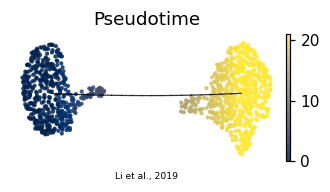

In [10]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.10
# map fitted curve nodes through the SAME rigid rotation + flip applied to cells
F = adata.uns['graph']['F'].T
Fc = (F - adata.obsm['X_umap'].mean(0)) @ Rm.T
flip = np.average((c @ Rm.T)[:,0], weights=w) > 0
if flip: Fc[:,0] = -Fc[:,0]
B = np.asarray(adata.uns['graph']['B']); ii,jj = np.where(np.triu(B>0))
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
for a,b in zip(ii,jj): ax.plot([Fc[a,0],Fc[b,0]],[Fc[a,1],Fc[b,1]], '-', c='k', lw=.8, alpha=.8, zorder=5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.14,'Li et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')